In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

'/projectnb/batmanlab/mragoza/lung-project/notebooks/copdgene'

In [2]:
import sys, os

print(os.getpid())

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

def add_path(p: str):
    if p not in sys.path:
        sys.path.append(p)

add_path(os.environ['LP_ROOT'])
add_path(os.environ['PROJECT'])

import project

import torch
assert torch.cuda.is_available()

952904


# Gather examples

In [3]:
from pathlib import Path

#data_root = Path(os.environ['LP_ROOT']) / 'data' / 'COPDGene'
data_root = Path(os.environ['PRIVATE']) / 'data' / 'COPDGene'

subject_file = data_root / 'sample1000_2025-07-22.csv'
subject_list = project.fileio.load_subject_list(subject_file, key='sid', sep='\t')

bad_subjects = ['23686J', '24634V'] # failed to generate mesh

subject_list = [sid for sid in subject_list if sid not in bad_subjects]

#oom_subjects = ['19760T', '19415C']
#subject_list = oom_subjects

len(subject_list)

Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/sample1000_2025-07-22.csv


998

In [4]:
config = project.fileio.load_config('2026-09-15_config.yaml')

data_config = config['dataset']
data_config['subjects'] = subject_list
data_config['pipeline_tags']['mesh_generation'] = 'rad'
data_config['pipeline_tags']['field_interpolation'] = 'fix'
data_config['pipeline_tags']['forward_simulation'] = 'LE'

project.utils.pprint(data_config)

Loading 2026-09-15_config.yaml
dict(len=6)
├── 'name':          'COPDGene'
├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/COPDGene'
├── 'subjects':      list(len=998)
|   ├── 0: '16514P'
|   ├── 1: '20748Q'
|   ├── 2: '11007Z'
|   ├── 3: '14771Z'
|   ├── 4: '13651K'
|   ├── 5: '15900P'
|   ├── 6: '15312Y'
|   ├── 7: '21042H'
|   ├── 8: '21877G'
|   ├── 9: '10127E'
|   └── <988 more items>
├── 'state_pairs':   list(len=1)
|   └── 0: list(len=2)
├── 'variant':       '2026-09-15'
└── 'pipeline_tags': dict(len=8)
    ├── 'image_resampling':    'iso'
    ├── 'image_segmentation':  'v3d'
    ├── 'image_registration':  'gil'
    ├── 'anatomical_regions':  'lung'
    ├── 'material_properties': 'bela'
    ├── 'mesh_generation':     'rad'
    ├── 'field_interpolation': 'fix'
    └── 'forward_simulation':  'LE'


In [5]:
examples = project.get_examples(data_config)

Gathering examples...
998 total


# Training run

In [6]:
train_config = config['training']
project.utils.pprint(train_config)

dict(len=9)
├── 'seed':       1234
├── 'task':       dict(len=3)
|   ├── 'inputs':  list(len=1)
|   ├── 'targets': list(len=1)
|   └── 'losses':  dict(len=1)
├── 'split':      dict(len=3)
|   ├── 'key':        'category'
|   ├── 'test_ratio': 0.2
|   └── 'val_ratio':  0.1
├── 'transform':  dict(len=8)
|   ├── 'normalize':      True
|   ├── 'image_mean':     0.0
|   ├── 'image_std':      1.0
|   ├── 'apply_mask':     True
|   ├── 'do_augment':     True
|   ├── 'rand_rotate':    True
|   ├── 'rand_reflect':   True
|   └── 'rand_translate': 4.0
├── 'loader':     dict(len=3)
|   ├── 'batch_size':  1
|   ├── 'shuffle':     True
|   └── 'num_workers': 0
├── 'model':      dict(len=2)
|   ├── 'backbone': dict(len=11)
|   └── 'heads':    dict(len=1)
├── 'pde_solver': dict(len=5)
|   ├── 'type':          'warp'
|   ├── 'material_type': 'linear'
|   ├── 'g_vector':      list(len=3)
|   ├── 'relative_loss': True
|   └── 'tv_reg_weight': 1e-05
├── 'optimizer':  dict(len=2)
|   ├── 'type': 'AdamW'
|

In [9]:
train_config = {
    'seed': 1234,
    'task': {
        'inputs':  ['image'],
        'targets': ['E'],
        'losses':  {'E': 'sim'}
    },
    'split': {'method': 'random', 'test_ratio': 0.1, 'val_ratio': 0.1},
    'transform': {
        'normalize': False,
        'apply_mask': False,
        'do_augment': False,
        'rand_rotate': False,
        'rand_reflect': False,
        'rand_translate': 0.0,
        'use_cache': False
    },
    'loaders': {'batch_size': 1, 'shuffle': True},
    'model': {
        'backbone': {
            'type': 'UNet3D',
            'out_channels': 8,
            'n_conv_units': 2,
            'n_unet_levels': 2,
            'do_downsample': True
        },
        'heads': {
            'E': {
                'mode': 'log10',
                'scale': 1.0,
                'v_loc': 2e3,
                'v_min': 0.0,
                'v_max': 1e5
            }
        }
    },
    'optimizer': {'type': 'AdamW', 'lr': 1e-3},
    'pde_solver': {
        'type': 'warp.fem',
        'material_type': 'linear',
        'g_vector': [0, -9.81, 0]
    },
    'boundary_condition': {'type': 'mesh_key', 'value': 'u_fwd'},
    'trainer': {'num_epochs': 10, 'save_interval': 1}
}

In [ ]:
%autoreload
project.run_training(examples, train_config, out_name='2026-10-20_LE_downsample')

Splitting data examples
Train examples: 798
Test examples:  100
Val examples:   100
Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
MultiTaskModel(
  (backbone): UNet3D(
    (encoder): ConvBlock3D(
      (unit0): ConvUnit3D(
        (conv): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
        (norm): GroupNorm(4, 8, eps=1e-05, affine=True)
        (act): LeakyReLU(negative_slope=0.1, inplace=True)
      )
      (unit1): ConvUnit3D(
        (conv): Conv3d(8, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
        (norm): GroupNorm(4, 8, eps=1e-05, affine=True)
        (act): LeakyReLU(negative_slope=0.1, inplace=True)
      )
    )
    (sublevel): UNet3D(
      (encoder): ConvBlock3D(
        (unit0): ConvUnit3D(
          (conv): Conv3d(8, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=

Training start
Saving outputs/training/2026-10-20_LE_downsample/checkpoint00000.pt
[Epoch 0 | test batch 0 | load data]  dt = 3.5s  mem_used = 4.7 GiB  subject = 22667A  img_size = (325, 325, 381)  n_verts = 68785
[Epoch 0 | test batch 0 | run batch]  dt = 4.1s  mem_used = 4.7 GiB  loss = 0.002736  grad_norm = 0
[Epoch 0 | test batch 1 | load data]  dt = 3.6s  mem_used = 4.7 GiB  subject = 13533E  img_size = (350, 350, 329)  n_verts = 69806
[Epoch 0 | test batch 1 | run batch]  dt = 5.8s  mem_used = 4.8 GiB  loss = 0.003845  grad_norm = 0
[Epoch 0 | test batch 2 | load data]  dt = 2.5s  mem_used = 4.8 GiB  subject = 10155J  img_size = (282, 282, 315)  n_verts = 36876
[Epoch 0 | test batch 2 | run batch]  dt = 2s  mem_used = 4.8 GiB  loss = 0.002519  grad_norm = 0
[Epoch 0 | test batch 3 | load data]  dt = 3.7s  mem_used = 4.8 GiB  subject = 23293Q  img_size = (280, 280, 324)  n_verts = 60774
[Epoch 0 | test batch 3 | run batch]  dt = 4.4s  mem_used = 4.8 GiB  loss = 0.004462  grad_norm

In [18]:
import pandas as pd
df = pd.read_csv('outputs/training/metrics.csv')
df

,epoch,phase,batch,loss,group,label,num_voxels,E_vox.mean,E_vox.std,E_vox.rms,...,u_cell.std,u_cell.rms,u_cell.mae,u_cell.mre,u_cell.rmse,u_cell.nrmse,res_cell.mean,res_cell.std,res_cell.rms,grad_norm
0,0,train,0,0.003250,NaN,NaN,5021400.0,836.638511,369.205268,914.481562,...,0.009443,0.021353,0.001188,0.062317,0.001423,0.067292,0.001014,0.002340,0.002550,0.100145
1,0,train,1,0.001805,NaN,NaN,2144006.0,1010.262168,338.375464,1065.423673,...,0.005036,0.014253,0.000859,0.067522,0.001079,0.078809,0.001794,0.003281,0.003740,0.068672
2,0,train,2,0.005448,NaN,NaN,5794073.0,1017.800553,184.727542,1034.428456,...,0.005576,0.011417,0.001000,0.096635,0.001299,0.109764,0.000739,0.001756,0.001905,0.077835
3,1,train,0,0.000561,NaN,NaN,2144006.0,955.570000,180.058764,972.386334,...,0.005217,0.013718,0.000472,0.037133,0.000594,0.043384,0.001740,0.003125,0.003577,0.019282
4,1,train,1,0.002937,NaN,NaN,5794073.0,929.382378,173.935458,945.518455,...,0.005713,0.011485,0.000737,0.071178,0.000949,0.080185,0.000691,0.001662,0.001800,0.031918
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1053,0,train,793,0.000510,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.009547
1054,0,train,794,0.000379,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.005190
1055,0,train,795,0.000558,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.006146
1056,0,train,796,0.001897,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.028224


In [21]:
df.groupby(['epoch', 'phase'])[['loss']].describe()

loss                                                        \
             count      mean       std           min       25%       50%   
epoch phase                                                                
0     test   100.0  0.003392  0.002611  5.009743e-06  0.002052  0.002810   
      train  804.0  0.001327  0.001577  5.980634e-07  0.000476  0.000822   
      val    100.0  0.003488  0.002466  5.202605e-04  0.002061  0.002745   
1     train    6.0  0.001884  0.001086  5.582449e-04  0.000958  0.002148   
2     train    6.0  0.001239  0.000415  7.305304e-04  0.000885  0.001347   
3     train    6.0  0.001111  0.000221  8.258781e-04  0.000926  0.001207   
4     train    6.0  0.001075  0.000706  4.549815e-04  0.000556  0.000790   
5     train    6.0  0.001070  0.000686  3.553222e-04  0.000512  0.000962   
6     train    6.0  0.000715  0.000305  4.122284e-04  0.000479  0.000633   
7     train    6.0  0.000742  0.000179  5.859503e-04  0.000620  0.000659   
8     train    6.0  0.000724  0.000111  6.071992e-04  0.000625  0.000717   
9     train    6.0  0.000614  0.000207  3.977164e-04  0.000443  0.000581   

                                 
                  75%       max  
epoch phase                      
0     test   0.004141  0.019909  
      train  0.001550  0.013151  
      val    0.003953  0.016635  
1     train  0.002740  0.002955  
2     train  0.001558  0.001653  
3     train  0.001257  0.001318  
4     train  0.001638  0.002016  
5     train  0.001610  0.001950  
6     train  0.000971  0.001097  
7     train  0.000885  0.000980  
8     train  0.000803  0.000875  
9     train  0.000792  0.000865

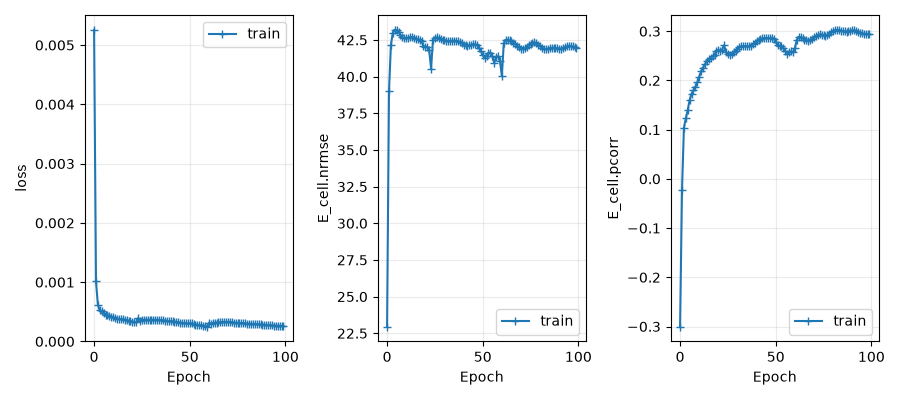

In [16]:
import matplotlib.pyplot as plt

def plot_training(df, metrics=['loss', 'E_cell.nrmse', 'E_cell.pcorr']):
    n_axes = len(metrics)
    
    curves = df.groupby(['epoch', 'phase'])[metrics].mean()

    fig, axes = plt.subplots(1, n_axes, figsize=(3*n_axes, 4), squeeze=False)
    axes = axes.ravel()

    for ax, metric in zip(axes, metrics):
        values = curves[metric].unstack('phase').sort_index()

        for phase in ['train', 'val', 'test']:
            if phase in values:
                series = values[phase].dropna()
                ax.plot(series.index, series, marker='+', label=phase)
        
        ax.set(xlabel='Epoch', ylabel=metric)
        ax.legend()
        ax.grid(alpha=0.25)

    fig.tight_layout()
    return fig

fig = plot_training(df)
plt.pause(3.0)

In [17]:
ex = examples[0]

nifti = project.fileio.load_nibabel(ex.paths['input_image'])
image = nifti.get_fdata()
affine = nifti.affine

mask = project.fileio.load_nibabel(ex.paths['anatomical_map']).get_fdata() > 0

E_true = project.fileio.load_nibabel(ex.paths['material_dir'] / 'youngs_modulus.nii.gz').get_fdata()

Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/images/16514P_EXP_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/masks/16514P_EXP_iso_v3d_lung.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/COPDGene/Processed/2026-09-15/16514P/fields/16514P_EXP_iso_v3d_bela/youngs_modulus.nii.gz


In [18]:
import project.training
trainer = project.training.get_trainer(examples, train_config)

Splitting data examples
Train examples: 1
Test examples:  0
Val examples:   0


Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
MultiTaskModel(
  (backbone): UNet3D(
    (encoder): ConvBlock3D(
      (unit0): ConvUnit3D(
        (conv): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
        (norm): GroupNorm(4, 8, eps=1e-05, affine=True)
        (act): LeakyReLU(negative_slope=0.1, inplace=True)
      )
      (unit1): ConvUnit3D(
        (conv): Conv3d(8, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
        (norm): GroupNorm(4, 8, eps=1e-05, affine=True)
        (act): LeakyReLU(negative_slope=0.1, inplace=True)
      )
    )
    (unet): UNet3D(
      (encoder): ConvBlock3D(
        (unit0): ConvUnit3D(
          (conv): Conv3d(8, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=same, bias=False, padding_mode=replicate)
          (norm): GroupNorm(4, 16, eps=1e-05, affine=True)
          (act): L

In [23]:
batch = next(iter(trainer.train_loader))
project.utils.pprint(batch)

dict(len=7)
├── 'example':  list(len=1)
|   └── 0: Example()
├── 'affine':   Tensor(shape=torch.Size([1, 4, 4]), dtype=torch.float32, device=cpu)
|   └── 0: Tensor(shape=torch.Size([4, 4]), dtype=torch.float32, device=cpu)
├── 'image':    Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.float32, device=cpu)
|   └── 0: Tensor(shape=torch.Size([1, 368, 368, 268]), dtype=torch.float32, device=cpu)
├── 'mask':     Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.bool, device=cpu)
|   └── 0: Tensor(shape=torch.Size([1, 368, 368, 268]), dtype=torch.bool, device=cpu)
├── 'mesh':     list(len=1)
|   └── 0: Mesh()
├── 'material': Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.int64, device=cpu)
|   └── 0: Tensor(shape=torch.Size([1, 368, 368, 268]), dtype=torch.int64, device=cpu)
└── 'anatomy':  Tensor(shape=torch.Size([1, 1, 368, 368, 268]), dtype=torch.int64, device=cpu)
    └── 0: Tensor(shape=torch.Size([1, 368, 368, 268]), dtype=torch.int64, device=cpu)


In [24]:
outputs = trainer.run_batch(batch, eval_mode=True)[1]
project.utils.pprint(outputs)

OutOfMemoryError: CUDA out of memory. Tried to allocate 3.25 GiB. GPU 0 has a total capacity of 44.42 GiB of which 3.00 GiB is free. Including non-PyTorch memory, this process has 41.41 GiB memory in use. Of the allocated memory 38.63 GiB is allocated by PyTorch, and 2.12 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [21]:
E_pred = outputs['preds']['E'].detach().cpu().numpy()[0,0]
E_true.shape, E_pred.shape

((368, 368, 268), (368, 368, 268))

In [22]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt

img_kws = dict(cmap='gray', vmin=-1000, vmax=-500)
E_t_kws = dict(cmap='jet', vmin=0, vmax=1e4)
E_p_kws = dict(cmap='jet', vmin=0, vmax=1e4)
err_kws = dict(cmap='seismic', vmin=-1, vmax=1)

grid_kws = dict(cbar_width=0.2, padding=(0.5, 0.65, 0.35, 0.3))

In [19]:
import numpy as np

img_m = image * mask
E_t_m = E_true * mask
E_p_m = E_pred * mask

err_m = np.log10(np.maximum(E_pred / E_true, 1e-12)) * mask

z = E_true.shape[-1] // 2
z

134

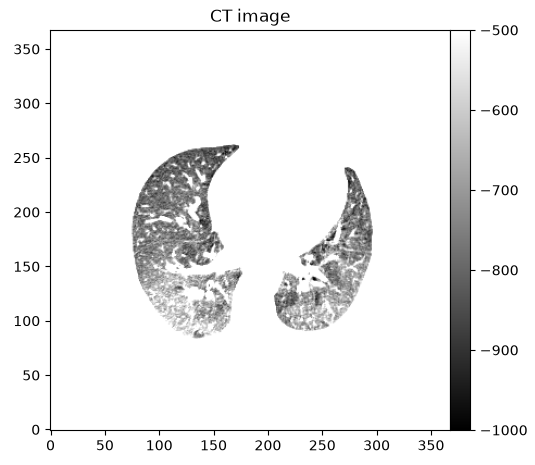

In [20]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('CT image')
im = ax[0,0].imshow(img_m[:,:,z].T, origin='lower', **img_kws)
plt.colorbar(im, cax)

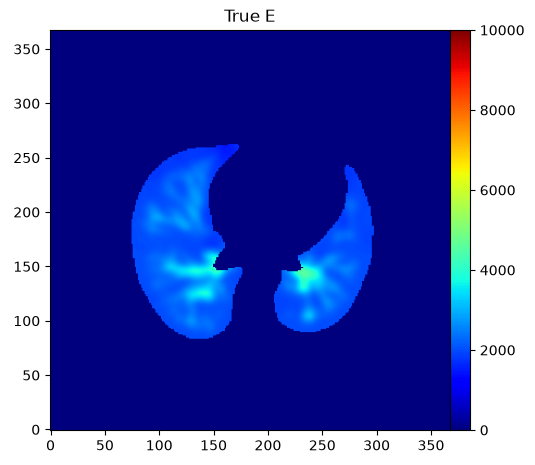

In [21]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('True E')
im = ax[0,0].imshow(E_t_m[:,:,z].T, origin='lower', **E_t_kws)
plt.colorbar(im, cax)

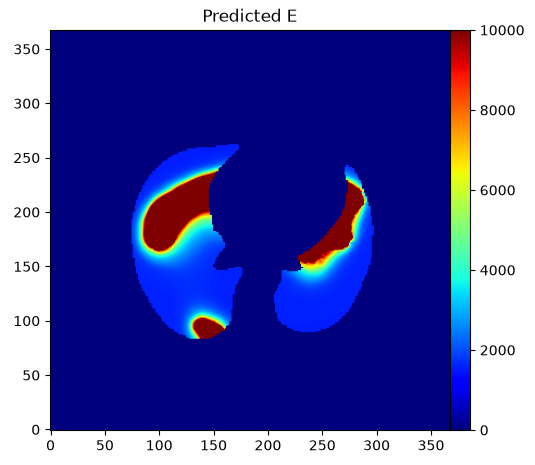

In [22]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('Predicted E')
im = ax[0,0].imshow(E_p_m[:,:,z].T, origin='lower', **E_p_kws)
plt.colorbar(im, cax)

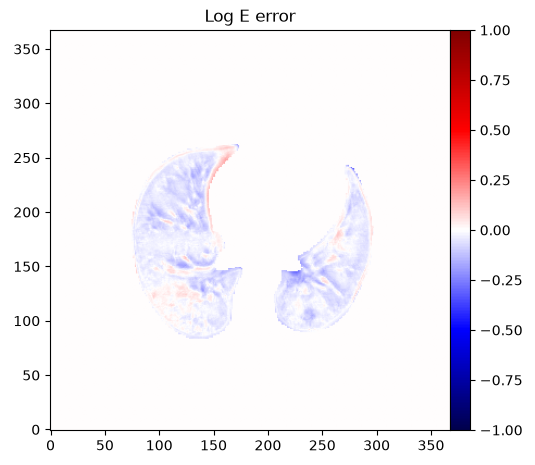

In [34]:
fig, ax, cax = mpl_viz.subplot_grid(1, 1, 4, 4, **grid_kws)
ax[0,0].set_title('Log E error')
im = ax[0,0].imshow(err_m[:,:,z].T, origin='lower', **err_kws)
plt.colorbar(im, cax)